
# Movie Recommendation System

### Machine Learning Internship Project

**Objective:** Build a movie recommendation system using Machine Learning.

### Algorithms Used
1. Content-Based Filtering
2. Collaborative Filtering
3. K-Nearest Neighbors (KNN)
4. Cosine Similarity

**Dataset:** MovieLens Latest Small Dataset


## 1. Import Required Libraries

In [1]:

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from pathlib import Path
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.neighbors import NearestNeighbors
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error

import warnings
warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")

print("All libraries imported successfully!")


All libraries imported successfully!


## 2. Load MovieLens Dataset

In [2]:

# Find project root whether notebook runs from root or notebooks/
current = Path.cwd()

if (current / "dataset").exists():
    PROJECT_ROOT = current
elif (current.parent / "dataset").exists():
    PROJECT_ROOT = current.parent
else:
    raise FileNotFoundError(
        "Cannot find dataset folder. Run the notebook from the project "
        "root or notebooks folder."
    )

DATASET_PATH = PROJECT_ROOT / "dataset"

movies = pd.read_csv(DATASET_PATH / "movies.csv")
ratings = pd.read_csv(DATASET_PATH / "ratings.csv")

print("Movies shape:", movies.shape)
print("Ratings shape:", ratings.shape)

display(movies.head())
display(ratings.head())


Movies shape: (9742, 3)
Ratings shape: (100836, 4)


,movieId,title,genres
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,2,Jumanji (1995),Adventure|Children|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance
3,4,Waiting to Exhale (1995),Comedy|Drama|Romance
4,5,Father of the Bride Part II (1995),Comedy


,userId,movieId,rating,timestamp
0,1,1,4.0,964982703
1,1,3,4.0,964981247
2,1,6,4.0,964982224
3,1,47,5.0,964983815
4,1,50,5.0,964982931


## 3. Dataset Information

In [3]:

print("Movies Information:")
movies.info()

print("\nRatings Information:")
ratings.info()

print("\nMissing Values in Movies:")
display(movies.isnull().sum())

print("\nMissing Values in Ratings:")
display(ratings.isnull().sum())

print("\nNumber of unique movies:", movies["movieId"].nunique())
print("Number of unique users:", ratings["userId"].nunique())


Movies Information:
<class 'pandas.DataFrame'>
RangeIndex: 9742 entries, 0 to 9741
Data columns (total 3 columns):
 #   Column   Non-Null Count  Dtype
---  ------   --------------  -----
 0   movieId  9742 non-null   int64
 1   title    9742 non-null   str  
 2   genres   9742 non-null   str  
dtypes: int64(1), str(2)
memory usage: 228.5 KB

Ratings Information:
<class 'pandas.DataFrame'>
RangeIndex: 100836 entries, 0 to 100835
Data columns (total 4 columns):
 #   Column     Non-Null Count   Dtype  
---  ------     --------------   -----  
 0   userId     100836 non-null  int64  
 1   movieId    100836 non-null  int64  
 2   rating     100836 non-null  float64
 3   timestamp  100836 non-null  int64  
dtypes: float64(1), int64(3)
memory usage: 3.1 MB

Missing Values in Movies:


movieId    0
title      0
genres     0
dtype: int64


Missing Values in Ratings:


userId       0
movieId      0
rating       0
timestamp    0
dtype: int64


Number of unique movies: 9742
Number of unique users: 610


## 4. Data Preprocessing

In [4]:

# Remove duplicate records
movies = movies.drop_duplicates(subset="movieId").copy()
ratings = ratings.drop_duplicates(
    subset=["userId", "movieId"]
).copy()

# Remove missing values
movies = movies.dropna(subset=["movieId", "title", "genres"])
ratings = ratings.dropna(
    subset=["userId", "movieId", "rating"]
)

# Clean genre information
movies["genres"] = movies["genres"].replace(
    "(no genres listed)", ""
)

# Extract release year
movies["year"] = movies["title"].str.extract(
    r"\((\d{4})\)"
)

# Prepare content features
movies["content"] = (
    movies["genres"].str.replace("|", " ", regex=False)
)

print("Data preprocessing completed!")
print("Clean movies:", movies.shape)
print("Clean ratings:", ratings.shape)

display(movies.head())


Data preprocessing completed!
Clean movies: (9742, 5)
Clean ratings: (100836, 4)


,movieId,title,genres,year,content
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy,1995,Adventure Animation Children Comedy Fantasy
1,2,Jumanji (1995),Adventure|Children|Fantasy,1995,Adventure Children Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance,1995,Comedy Romance
3,4,Waiting to Exhale (1995),Comedy|Drama|Romance,1995,Comedy Drama Romance
4,5,Father of the Bride Part II (1995),Comedy,1995,Comedy


## 5. Exploratory Data Analysis

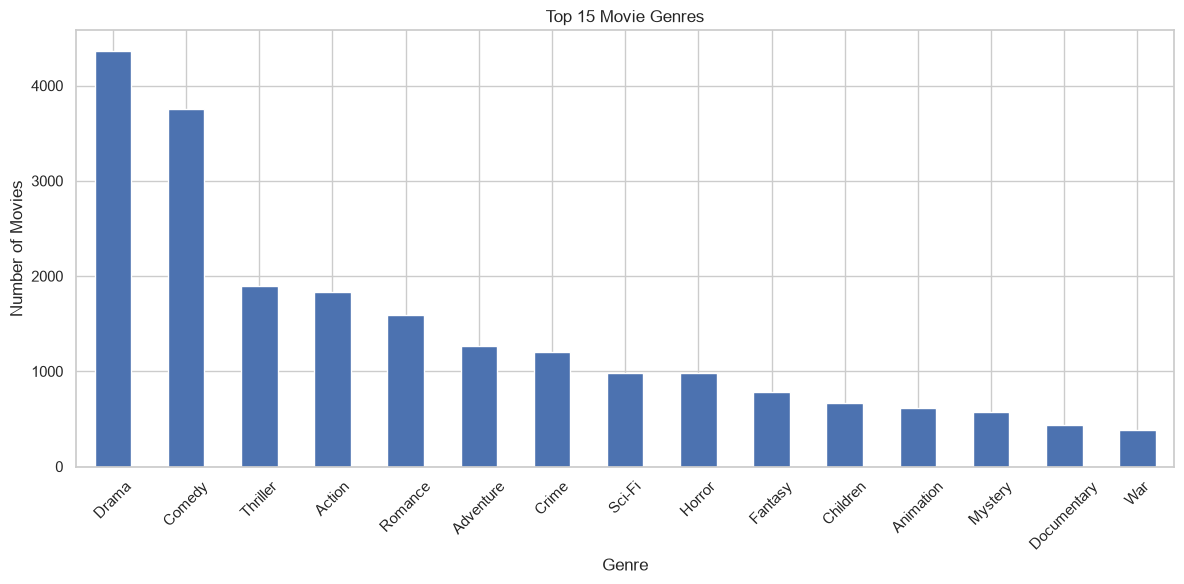

In [5]:

# Genre distribution
genre_data = movies.assign(
    genre=movies["genres"].str.split("|")
).explode("genre")

genre_data = genre_data[
    genre_data["genre"].notna() &
    (genre_data["genre"] != "")
]

plt.figure(figsize=(12, 6))
genre_data["genre"].value_counts().head(15).plot(
    kind="bar"
)

plt.title("Top 15 Movie Genres")
plt.xlabel("Genre")
plt.ylabel("Number of Movies")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


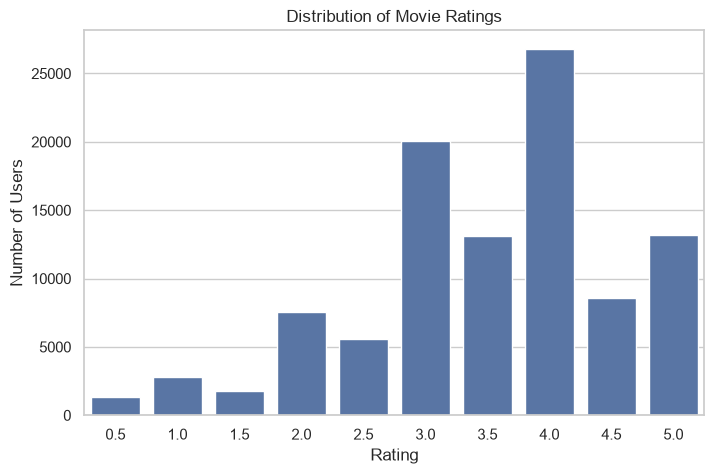

Average movie rating: 3.501556983616962


In [6]:

# Rating distribution
plt.figure(figsize=(8, 5))

sns.countplot(
    data=ratings,
    x="rating"
)

plt.title("Distribution of Movie Ratings")
plt.xlabel("Rating")
plt.ylabel("Number of Users")

plt.show()

print("Average movie rating:", ratings["rating"].mean())


## 6. Popular Movie Analysis

In [7]:

movie_stats = ratings.groupby("movieId").agg(
    average_rating=("rating", "mean"),
    rating_count=("rating", "count")
).reset_index()

# Require at least 20 ratings for popular movie ranking
popular_movies = movie_stats[
    movie_stats["rating_count"] >= 20
].merge(
    movies[["movieId", "title", "genres"]],
    on="movieId"
)

popular_movies = popular_movies.sort_values(
    ["average_rating", "rating_count"],
    ascending=[False, False]
)

print("Top 10 Popular Movies:")
display(popular_movies.head(10))


Top 10 Popular Movies:


,movieId,average_rating,rating_count,title,genres
292,1104,4.475000,20,"Streetcar Named Desire, A (1951)",Drama
105,318,4.429022,317,"Shawshank Redemption, The (1994)",Crime|Drama
248,922,4.333333,27,Sunset Blvd. (a.k.a. Sunset Boulevard) (1950),Drama|Film-Noir|Romance
233,898,4.310345,29,"Philadelphia Story, The (1940)",Comedy|Drama|Romance
313,1204,4.300000,45,Lawrence of Arabia (1962),Adventure|Drama|War
153,475,4.300000,25,In the Name of the Father (1993),Drama
79,246,4.293103,29,Hoop Dreams (1994),Documentary
230,858,4.289062,192,"Godfather, The (1972)",Crime|Drama
333,1235,4.288462,26,Harold and Maude (1971),Comedy|Drama|Romance
1296,168252,4.280000,25,Logan (2017),Action|Sci-Fi


## 7. Content-Based Filtering Using TF-IDF

In [8]:

tfidf = TfidfVectorizer(
    stop_words="english"
)

tfidf_matrix = tfidf.fit_transform(
    movies["content"].fillna("")
)

print("TF-IDF matrix shape:", tfidf_matrix.shape)
print("Content-Based Filtering completed!")


TF-IDF matrix shape: (9742, 21)
Content-Based Filtering completed!


## 8. Cosine Similarity

In [9]:

cosine_sim = cosine_similarity(
    tfidf_matrix,
    dense_output=False
)

movie_indices = pd.Series(
    movies.index,
    index=movies["title"]
).drop_duplicates()

def recommend_movies(movie_title, n=10):

    if movie_title not in movie_indices.index:
        print("Movie not found!")
        return pd.DataFrame()

    idx = movie_indices[movie_title]

    scores = cosine_sim[idx].toarray().flatten()

    similar_indices = np.argsort(scores)[::-1]

    similar_indices = [
        i for i in similar_indices if i != idx
    ][:n]

    result = movies.iloc[similar_indices][
        ["movieId", "title", "genres"]
    ].copy()

    result["similarity_score"] = scores[similar_indices]

    return result.reset_index(drop=True)


print("Recommendations for Toy Story:")
display(recommend_movies("Toy Story (1995)", 10))


Recommendations for Toy Story:


,movieId,title,genres,similarity_score
0,103755,Turbo (2013),Adventure|Animation|Children|Comedy|Fantasy,1.0
1,4016,"Emperor's New Groove, The (2000)",Adventure|Animation|Children|Comedy|Fantasy,1.0
2,3754,"Adventures of Rocky and Bullwinkle, The (2000)",Adventure|Animation|Children|Comedy|Fantasy,1.0
3,3114,Toy Story 2 (1999),Adventure|Animation|Children|Comedy|Fantasy,1.0
4,91355,Asterix and the Vikings (Astérix et les Viking...,Adventure|Animation|Children|Comedy|Fantasy,1.0
5,2294,Antz (1998),Adventure|Animation|Children|Comedy|Fantasy,1.0
6,45074,"Wild, The (2006)",Adventure|Animation|Children|Comedy|Fantasy,1.0
7,53121,Shrek the Third (2007),Adventure|Animation|Children|Comedy|Fantasy,1.0
8,136016,The Good Dinosaur (2015),Adventure|Animation|Children|Comedy|Fantasy,1.0
9,4886,"Monsters, Inc. (2001)",Adventure|Animation|Children|Comedy|Fantasy,1.0


## 9. Collaborative Filtering Using KNN

In [10]:

# Create user-movie rating matrix
user_movie_matrix = ratings.pivot_table(
    index="movieId",
    columns="userId",
    values="rating"
).fillna(0)

print("User-Movie Matrix:", user_movie_matrix.shape)

# Train KNN model
knn_model = NearestNeighbors(
    metric="cosine",
    algorithm="brute"
)

knn_model.fit(user_movie_matrix)

print("KNN model trained successfully!")


User-Movie Matrix: (9724, 610)
KNN model trained successfully!


## 10. KNN Movie Recommendations

In [11]:

def knn_recommendations(movie_id, n=10):

    if movie_id not in user_movie_matrix.index:
        print("Movie ID not found!")
        return pd.DataFrame()

    movie_position = user_movie_matrix.index.get_loc(
        movie_id
    )

    distances, indices = knn_model.kneighbors(
        user_movie_matrix.iloc[[movie_position]],
        n_neighbors=min(n + 1, len(user_movie_matrix))
    )

    recommended_ids = user_movie_matrix.index[
        indices.flatten()
    ]

    similarities = 1 - distances.flatten()

    result = pd.DataFrame({
        "movieId": recommended_ids,
        "similarity_score": similarities
    })

    result = result[
        result["movieId"] != movie_id
    ]

    result = result.merge(
        movies[["movieId", "title", "genres"]],
        on="movieId"
    )

    return result.head(n).reset_index(drop=True)


print("Movies similar to Toy Story:")
display(knn_recommendations(1, 10))


Movies similar to Toy Story:


,movieId,similarity_score,title,genres
0,3114,0.572601,Toy Story 2 (1999),Adventure|Animation|Children|Comedy|Fantasy
1,480,0.565637,Jurassic Park (1993),Action|Adventure|Sci-Fi|Thriller
2,780,0.564262,Independence Day (a.k.a. ID4) (1996),Action|Adventure|Sci-Fi|Thriller
3,260,0.557388,Star Wars: Episode IV - A New Hope (1977),Action|Adventure|Sci-Fi
4,356,0.547096,Forrest Gump (1994),Comedy|Drama|Romance|War
5,364,0.541145,"Lion King, The (1994)",Adventure|Animation|Children|Drama|Musical|IMAX
6,1210,0.541089,Star Wars: Episode VI - Return of the Jedi (1983),Action|Adventure|Sci-Fi
7,648,0.538913,Mission: Impossible (1996),Action|Adventure|Mystery|Thriller
8,1265,0.534169,Groundhog Day (1993),Comedy|Fantasy|Romance
9,1270,0.530381,Back to the Future (1985),Adventure|Comedy|Sci-Fi


## 11. Model Evaluation

In [12]:

# Split ratings into training and testing sets
train_ratings, test_ratings = train_test_split(
    ratings,
    test_size=0.2,
    random_state=42
)

# User-average baseline prediction
user_means = train_ratings.groupby(
    "userId"
)["rating"].mean()

global_mean = train_ratings["rating"].mean()

predictions = (
    test_ratings["userId"]
    .map(user_means)
    .fillna(global_mean)
)

mae = mean_absolute_error(
    test_ratings["rating"],
    predictions
)

rmse = np.sqrt(
    mean_squared_error(
        test_ratings["rating"],
        predictions
    )
)

print("User Average Baseline Evaluation")
print("MAE:", round(mae, 4))
print("RMSE:", round(rmse, 4))


User Average Baseline Evaluation
MAE: 0.7386
RMSE: 0.9497



**Evaluation note:** MAE and RMSE above measure a simple user-average
rating prediction baseline. They do not directly measure the quality
of the content-based or KNN recommendation rankings.


## 12. Save Trained Models

In [13]:

MODEL_DIR = PROJECT_ROOT / "models"
MODEL_DIR.mkdir(exist_ok=True)

joblib.dump(
    movies,
    MODEL_DIR / "movie_data.pkl"
)

joblib.dump(
    tfidf,
    MODEL_DIR / "tfidf_vectorizer.pkl"
)

joblib.dump(
    cosine_sim,
    MODEL_DIR / "similarity_matrix.pkl"
)

joblib.dump(
    knn_model,
    MODEL_DIR / "knn_model.pkl"
)

joblib.dump(
    user_movie_matrix,
    MODEL_DIR / "user_movie_matrix.pkl"
)

print("All models saved successfully!")
print("Model directory:", MODEL_DIR)


All models saved successfully!
Model directory: d:\Data\sem5\Predictors\Movie-Recommendation-System\models



## 13. Project Conclusion

The Movie Recommendation System was developed using the MovieLens
dataset and Python Machine Learning libraries.

### Implemented Techniques

1. Content-Based Filtering
2. Collaborative Filtering
3. K-Nearest Neighbors
4. Cosine Similarity

### Key Features

- Movie data preprocessing
- Exploratory data analysis
- Popular movie analysis
- Movie similarity calculation
- Personalized recommendation techniques
- Model saving

### Future Enhancements

- Add movie posters.
- Build a Streamlit web application.
- Add user login and preferences.
- Implement Matrix Factorization.
- Evaluate recommendations using Precision@K and Recall@K.

**Project Status:** Initial Machine Learning notebook completed.
